# Finite-difference solution of a boundary-value problem

Central differences give a linear system for the interior values.

$$y''=-9.81,\qquad y(0)=0,\quad y(5)=50.$$ 

Maximum error: 1.42e-14


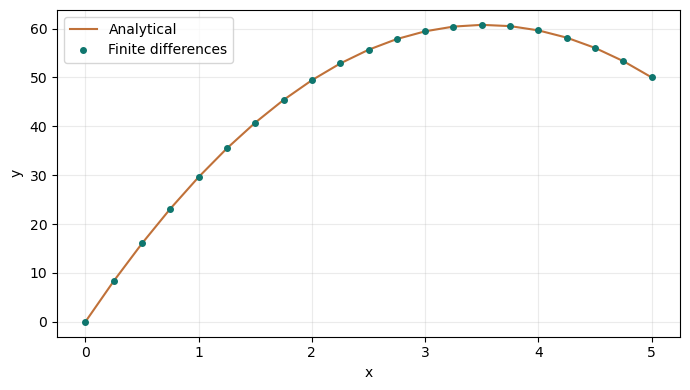

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 5, 21)
h = x[1]-x[0]
A = np.zeros((len(x), len(x)))
b = np.zeros(len(x))
A[0, 0] = A[-1, -1] = 1
b[-1] = 50
b[1:-1] = -9.81*h*h
for i in range(1, len(x)-1):
    A[i, i-1:i+2] = [1, -2, 1]
y = np.linalg.solve(A, b)
exact = -4.905*x*x + 34.525*x
assert np.allclose(y, exact, atol=1e-10)
print(f"Maximum error: {np.max(np.abs(y-exact)):.2e}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, exact, color='#c07139', label='Analytical')
ax.plot(x, y, 'o', color='#0f766e', markersize=4, label='Finite differences')
ax.set(xlabel='x', ylabel='y')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()